                                       CUSTOMER CHURN ANALYSIS AND SEGMENTATION                        

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [46]:
#Loading the data

df= pd.read_csv("/content/customer_churn_dataset_80000_records.csv")

In [3]:
#getting top 5 records
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22.0,Female,25.0,14,4,27,Basic,Monthly,598.0,9,1
1,2,41.0,Female,28.0,28,7,13,Standard,Monthly,584.0,20,0
2,3,47.0,Male,27.0,10,2,29,Premium,Annual,757.0,21,0
3,4,35.0,Male,9.0,12,5,17,Premium,Quarterly,232.0,18,0
4,5,53.0,Female,58.0,24,9,2,Standard,Annual,533.0,18,0


In [4]:
#Checking for the unique ids
df['CustomerID'].nunique()

79900

In [47]:
#It will used to display all the duplicate records in  sorted order
df[df['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
286,287,61.0,NaN,46.0,5,2,3,Premium,Annual,501.0,21,0
64383,287,61.0,NaN,46.0,5,2,3,Premium,Annual,501.0,21,0
649,650,61.0,Female,32.0,20,7,26,Basic,Quarterly,908.0,3,1
64428,650,61.0,Female,32.0,20,7,26,Basic,Quarterly,908.0,3,1
64376,928,56.0,Male,NaN,7,2,6,Premium,Annual,204.0,24,0
...,...,...,...,...,...,...,...,...,...,...,...,...
62198,62199,34.0,Female,19.0,10,10,29,Basic,Annual,219.0,22,1
62437,62438,44.0,Male,NaN,10,9,23,Basic,Quarterly,795.0,23,1
64391,62438,44.0,Male,NaN,10,9,23,Basic,Quarterly,795.0,23,1
62926,62927,55.0,Female,16.0,12,4,28,Premium,Annual,131.0,23,1


In [48]:
#Removing the duplicate records and keeping the first occurance
df = df.drop_duplicates(subset=['CustomerID'], keep='first')

In [49]:
df['CustomerID'].nunique()

79900

In [50]:
#Removing the unwanted columns
df.drop(columns=['CustomerID'],inplace=True)

In [51]:
#Checking the columns are dropped or not
df.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,22.0,Female,25.0,14,4,27,Basic,Monthly,598.0,9,1
1,41.0,Female,28.0,28,7,13,Standard,Monthly,584.0,20,0
2,47.0,Male,27.0,10,2,29,Premium,Annual,757.0,21,0
3,35.0,Male,9.0,12,5,17,Premium,Quarterly,232.0,18,0
4,53.0,Female,58.0,24,9,2,Standard,Annual,533.0,18,0


In [52]:
#gettting the shape of dataset
df.shape

(79900, 11)

In [53]:
#gettting the size of dataset
df.size

878900

In [54]:
#getting the info of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 79900 entries, 0 to 79999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                79256 non-null  float64
 1   Gender             79256 non-null  object 
 2   Tenure             79256 non-null  float64
 3   Usage Frequency    79900 non-null  int64  
 4   Support Calls      79900 non-null  int64  
 5   Payment Delay      79900 non-null  int64  
 6   Subscription Type  79256 non-null  object 
 7   Contract Length    79900 non-null  object 
 8   Total Spend        79256 non-null  float64
 9   Last Interaction   79900 non-null  int64  
 10  Churn              79900 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 7.3+ MB


In [55]:
#Getting the description of dataset
df.describe()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,79256.000000,79256.000000,79900.000000,79900.000000,79900.000000,79256.000000,79900.000000,79900.000000
mean,41.984115,32.108547,15.154205,5.405131,17.185507,548.656644,15.550839,0.472228
std,14.006524,18.817441,11.897544,3.521314,11.917430,1038.050485,11.755902,0.499231
min,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,42.000000,33.000000,15.000000,6.000000,18.000000,534.000000,15.000000,0.000000
75%,54.000000,47.000000,23.000000,8.000000,25.000000,769.000000,23.000000,1.000000
max,300.000000,1500.000000,1500.000000,300.000000,1500.000000,200000.000000,1500.000000,1.000000


In [56]:
#Checking for the duplicate records
df.duplicated().sum()

np.int64(14873)

In [57]:
#Removing the duplicate records from data
df.drop_duplicates(inplace=True)

In [58]:
#Checking the values are removed or not
df.duplicated().sum()

np.int64(0)

In [59]:
#Getting the categorical data columns
df.select_dtypes(include=['object']).columns

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object')

In [60]:
#Getting the numerical columns data
df.select_dtypes(include=['int64','float64']).columns

Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')

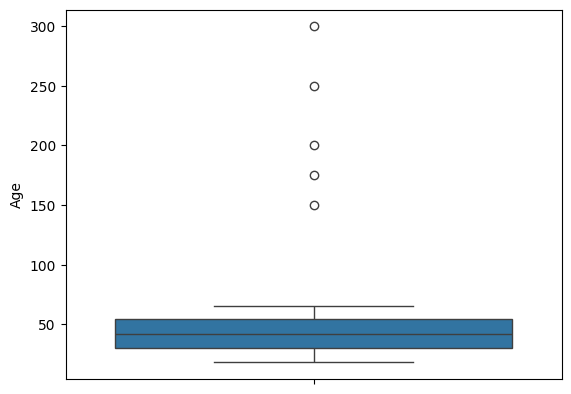

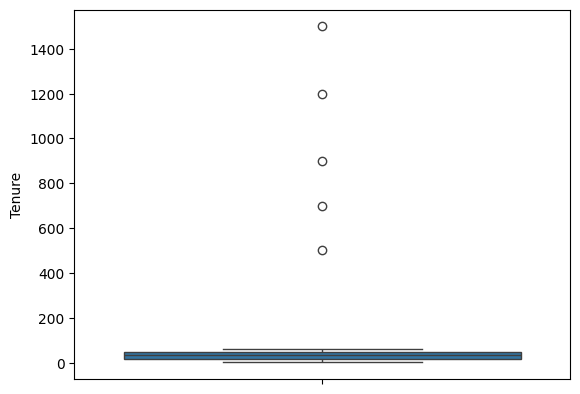

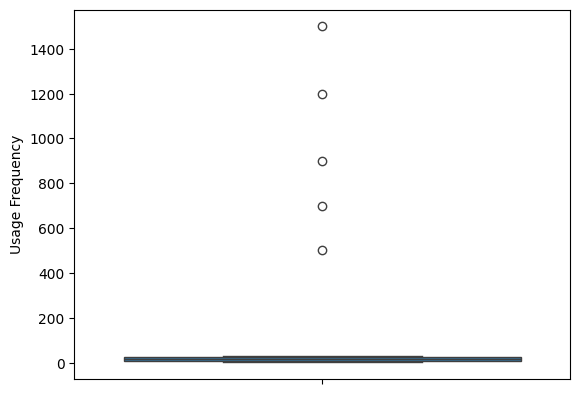

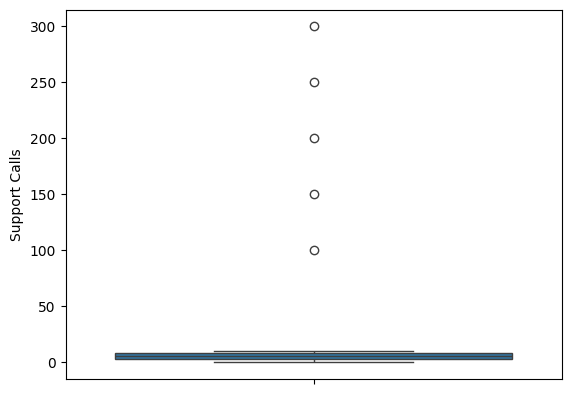

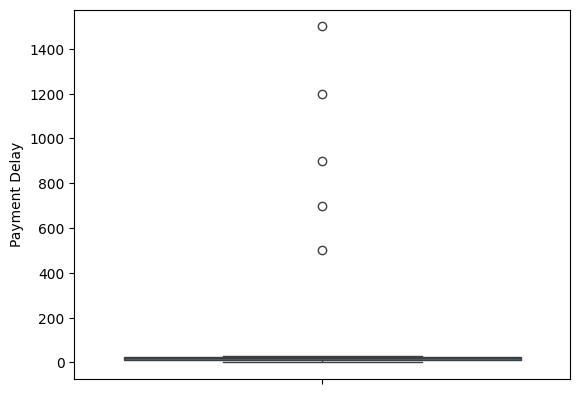

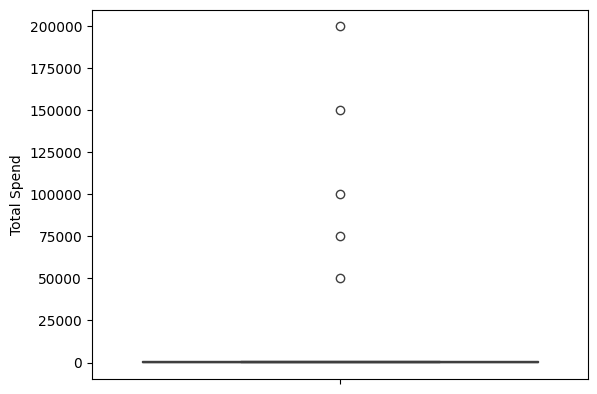

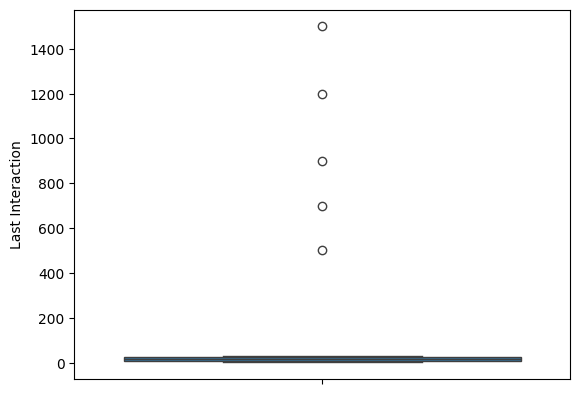

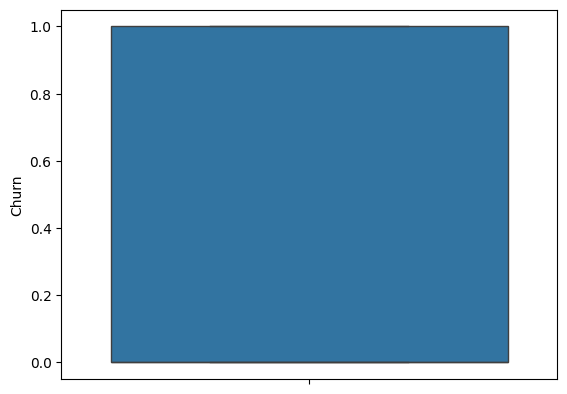

In [61]:
#Checking for outliers
for i in df.select_dtypes(include=['int64','float64']).columns:
    sns.boxplot(df[i])
    plt.show()

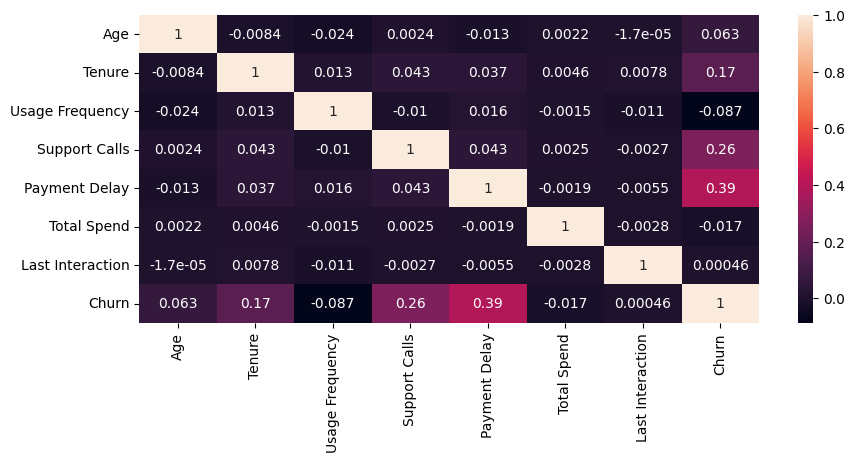

In [62]:
#Corelation between the numerical data
plt.figure(figsize=(10,4))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [21]:
#Dividing the data into feature and target
feat= df.drop(columns=['Churn'])
tar= df['Churn']

In [63]:
#Getting the top 5 records from feature
feat.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction
0,22.0,Female,25.0,14,4,27,Basic,Monthly,598.0,9
1,41.0,Female,28.0,28,7,13,Standard,Monthly,584.0,20
2,47.0,Male,27.0,10,2,29,Premium,Annual,757.0,21
3,35.0,Male,9.0,12,5,17,Premium,Quarterly,232.0,18
4,53.0,Female,58.0,24,9,2,Standard,Annual,533.0,18


In [64]:
#Splitting the data into train,test,split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(feat,tar,test_size=0.2, random_state=85)

In [65]:
#Getting the q1,q3,iqr,lowerbound and upperbound values for training dat
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns
q1= x_train[num_cols].quantile(0.25)
q3= x_train[num_cols].quantile(0.75)
iqr= q3 - q1
lower_bound= q1 - 1.5 * iqr
upper_bound= q3 + 1.5 * iqr


In [66]:
# Capping training data
x_train[num_cols] = x_train[num_cols].clip(
    lower=lower_bound,
    upper=upper_bound,
    axis=1
)

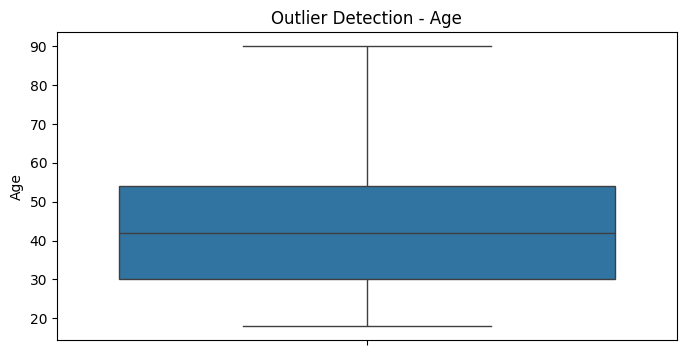

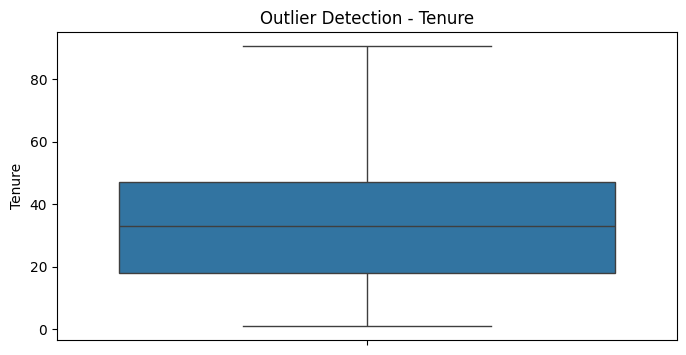

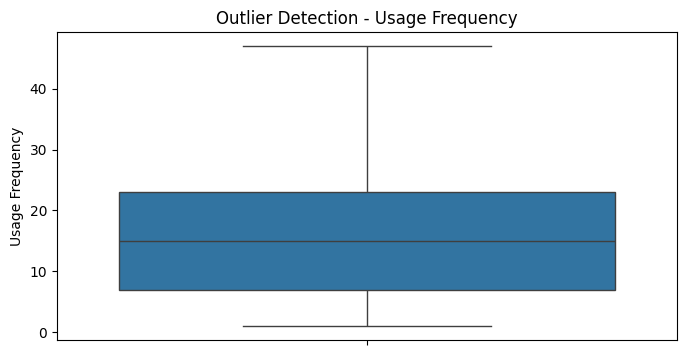

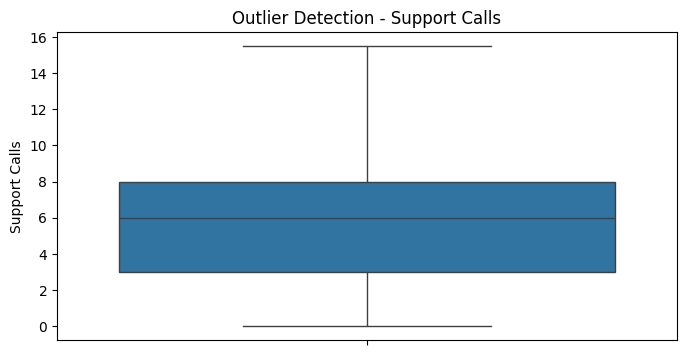

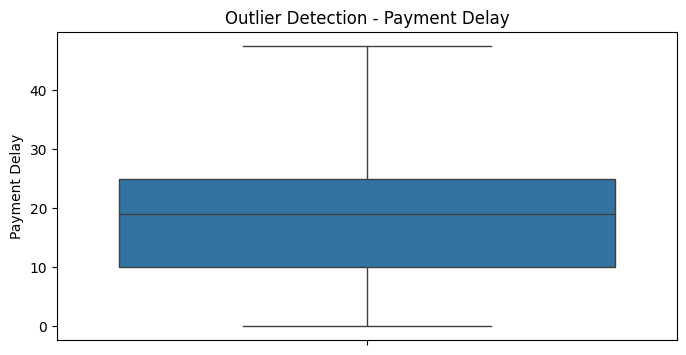

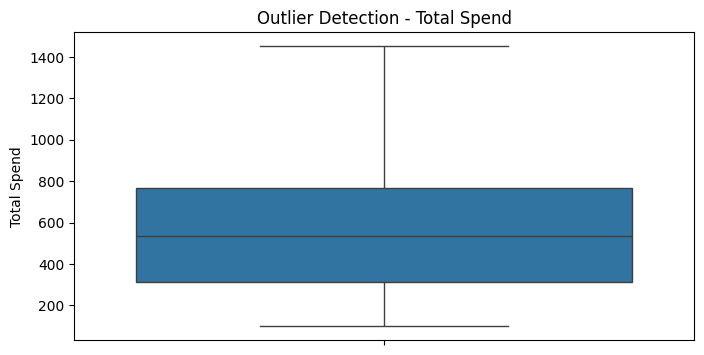

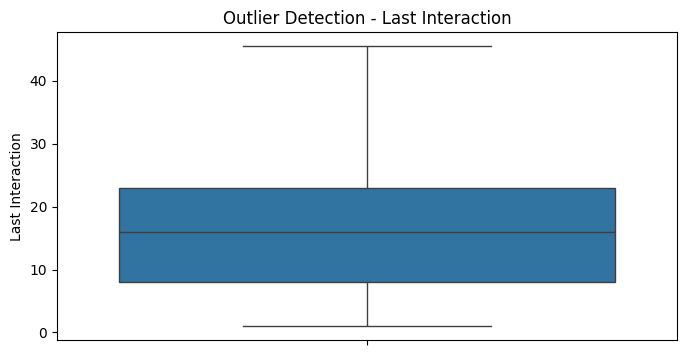

In [67]:
# Checking outliers in training data
for i in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x_train[i])
    plt.title(f'Outlier Detection - {i}')
    plt.show()

In [68]:
# Capping test data using training bounds
x_test[num_cols] = x_test[num_cols].clip(
    lower=lower_bound,
    upper=upper_bound,
    axis=1
)

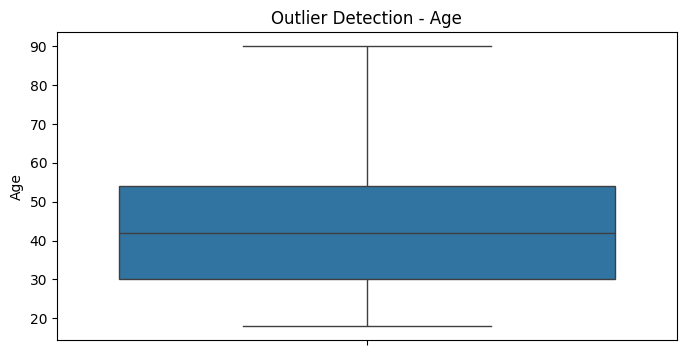

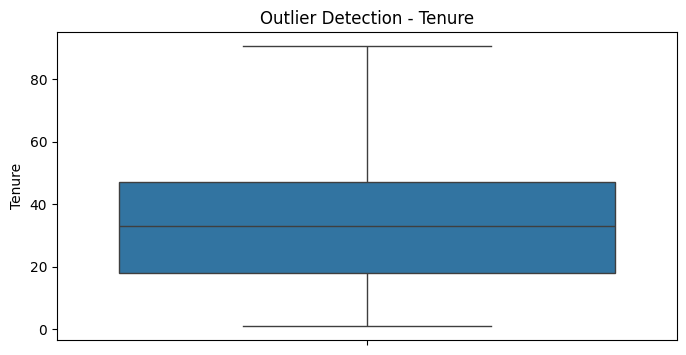

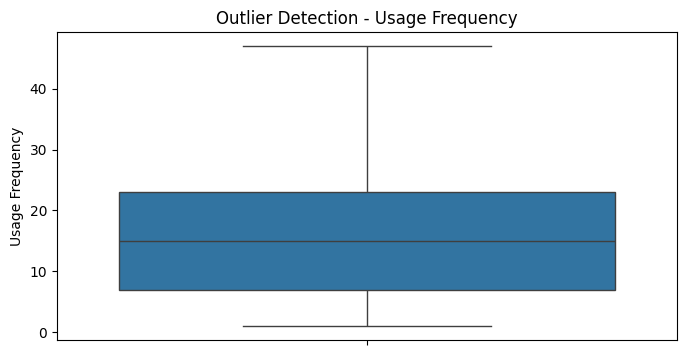

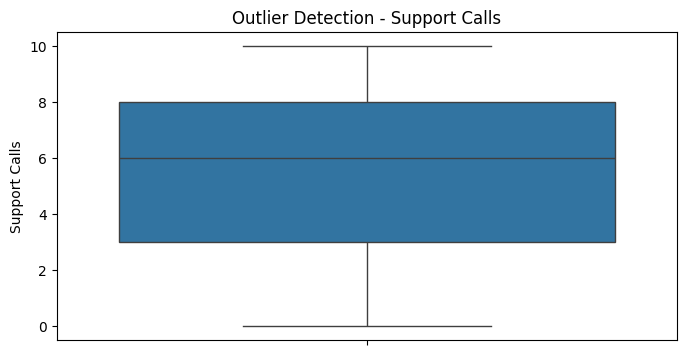

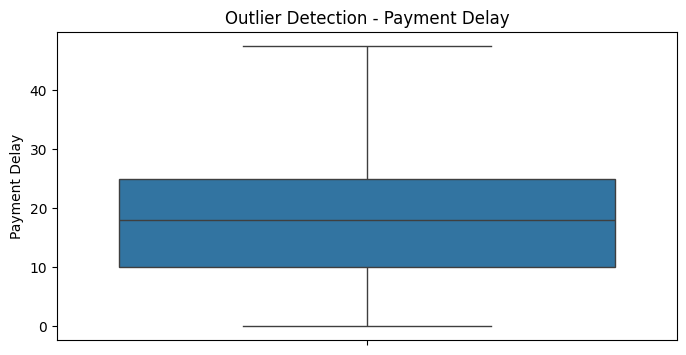

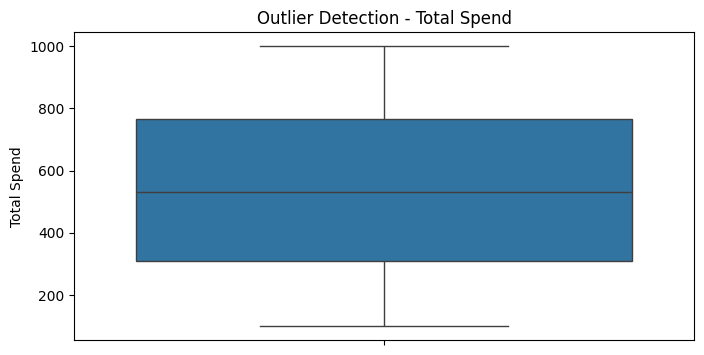

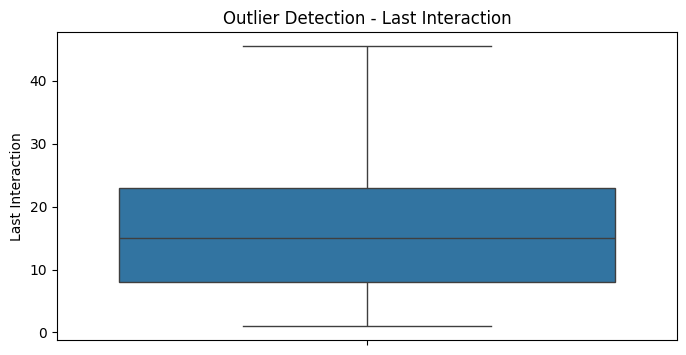

In [69]:
# Checking outliers in training data
for i in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x_test[i])
    plt.title(f'Outlier Detection - {i}')
    plt.show()

In [70]:
#Getting the categorical columns
df.select_dtypes(include=['object']).columns

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object')

In [71]:
# OneHot Encoding
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

cat_cols = ['Gender', 'Subscription Type', 'Contract Length']

train_encoded = encoder.fit_transform(x_train[cat_cols])
test_encoded = encoder.transform(x_test[cat_cols])

In [72]:
#Converting the values into the Tabular form of the encoding values
train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(),
    index=x_train.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoder.get_feature_names_out(),
    index=x_test.index
)
train_encoded.head()

,Gender_Female,Gender_Male,Gender_nan,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Subscription Type_nan,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
58633,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
56411,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
24061,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
52397,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3290,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [73]:
train_data = pd.concat([x_train[num_cols], train_encoded], axis=1)

In [74]:
train_data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Gender_nan,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Subscription Type_nan,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
58633,52.0,44.0,1,8.0,10.0,623.0,26.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
56411,38.0,35.0,24,5.0,21.0,902.0,18.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
24061,32.0,48.0,12,9.0,21.0,935.0,24.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
52397,27.0,21.0,6,5.0,28.0,NaN,13.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3290,21.0,26.0,13,9.0,28.0,524.0,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [75]:
train_data.shape

(52021, 17)

In [76]:
test_data = pd.concat([x_test[num_cols], test_encoded], axis=1)

In [77]:
test_data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Gender_nan,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Subscription Type_nan,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
33497,22.0,10.0,17,9,5.0,298.0,23.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
33870,37.0,41.0,29,3,24.0,NaN,24.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3224,58.0,47.0,20,6,24.0,328.0,6.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
38522,64.0,18.0,25,5,8.0,941.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
51556,51.0,26.0,23,3,21.0,348.0,22.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [78]:
test_data.shape

(13006, 17)

In [79]:
test_data.size

221102

In [80]:
#Checking the null values in train data column wise
train_data.isnull().sum()

,0
Age,519
Tenure,535
Usage Frequency,0
Support Calls,0
Payment Delay,0
Total Spend,517
Last Interaction,0
Gender_Female,0
Gender_Male,0
Gender_nan,0


In [81]:
#Checking the null values sum in train data
train_data.isnull().sum().sum()

np.int64(1571)

In [82]:
#null value percentage
train_data.isnull().sum().sum()/train_data.size*100

np.float64(0.1776431916070094)

In [83]:
#Data Imputation in training
# Replacing missing values with median
temp = train_data.select_dtypes(include=['int64', 'float64']).columns

for i in temp:
    train_data[i] = train_data[i].fillna(train_data[i].median())

In [84]:
#Checking null values are replaced or not
train_data.isnull().sum().sum()

np.int64(0)

In [85]:
#Checking the null values for test data column wise
test_data.isnull().sum()

,0
Age,125
Tenure,109
Usage Frequency,0
Support Calls,0
Payment Delay,0
Total Spend,127
Last Interaction,0
Gender_Female,0
Gender_Male,0
Gender_nan,0


In [86]:
#Checking the null values for test data
test_data.isnull().sum().sum()

np.int64(361)

In [87]:
#Data Imputation in testing
# Replacing missing values with median
temp1 = test_data.select_dtypes(include=['int64', 'float64']).columns

for i in temp1:
    test_data[i] = test_data[i].fillna(test_data[i].median())

In [88]:
#Checking the null values for test data
test_data.isnull().sum().sum()

np.int64(0)

In [89]:
#getting the shape of train and test data
print("x_train shape", x_train.shape)
print("x_test shape", x_test.shape)
print("y_train shape",y_train.shape)
print("y_test shape", y_test.shape)

x_train shape (52021, 10)
x_test shape (13006, 10)
y_train shape (52021,)
y_test shape (13006,)


In [90]:
train_data.columns

Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male',
       'Gender_nan', 'Subscription Type_Basic', 'Subscription Type_Premium',
       'Subscription Type_Standard', 'Subscription Type_nan',
       'Contract Length_Annual', 'Contract Length_Monthly',
       'Contract Length_Quarterly'],
      dtype='object')

In [91]:
#Scaling Tech
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
train_data[['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male',
       'Subscription Type_Basic', 'Subscription Type_Premium',
       'Subscription Type_Standard', 'Contract Length_Annual',
       'Contract Length_Monthly', 'Contract Length_Quarterly']]=scaler.fit_transform(train_data[['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
                                                                                         'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male',
                                                                                               'Subscription Type_Basic', 'Subscription Type_Premium',
                                                                                               'Subscription Type_Standard', 'Contract Length_Annual',
                                                                                               'Contract Length_Monthly', 'Contract Length_Quarterly']])
test_data[['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male',
       'Subscription Type_Basic', 'Subscription Type_Premium',
       'Subscription Type_Standard', 'Contract Length_Annual',
       'Contract Length_Monthly', 'Contract Length_Quarterly']]=scaler.transform(test_data[['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
                                                                                        'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male',
                                                                                             'Subscription Type_Basic', 'Subscription Type_Premium',
                                                                                               'Subscription Type_Standard', 'Contract Length_Annual',
                                                                                              'Contract Length_Monthly', 'Contract Length_Quarterly']])

In [92]:
train_data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Gender_nan,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Subscription Type_nan,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
58633,0.722525,0.706394,-1.600235,0.834606,-0.803480,0.314018,1.213292,0.948298,-0.929202,0.0,-0.699586,-0.699891,1.415765,0.0,1.420804,-0.726610,-0.691038
56411,-0.287806,0.177930,1.010420,-0.128487,0.437135,1.389522,0.287438,-1.054520,1.076192,0.0,-0.699586,1.428794,-0.706332,0.0,1.420804,-0.726610,-0.691038
24061,-0.720805,0.941267,-0.351661,1.155636,0.437135,1.516732,0.981829,0.948298,-0.929202,0.0,-0.699586,1.428794,-0.706332,0.0,1.420804,-0.726610,-0.691038
52397,-1.081637,-0.644125,-1.032702,-0.128487,1.226617,-0.029065,-0.291220,0.948298,-0.929202,0.0,1.429417,-0.699891,-0.706332,0.0,-0.703827,1.376254,-0.691038
3290,-1.514637,-0.350534,-0.238154,1.155636,1.226617,-0.067613,-1.564269,0.948298,-0.929202,0.0,1.429417,-0.699891,-0.706332,0.0,1.420804,-0.726610,-0.691038


In [93]:
test_data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Gender_nan,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Subscription Type_nan,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
33497,-1.442470,-1.290026,0.215872,1.155636,-1.367396,-0.938810,0.866097,-1.054520,1.076192,0.0,-0.699586,-0.699891,1.415765,0.0,-0.703827,1.376254,-0.691038
33870,-0.359972,0.530240,1.577953,-0.770549,0.775485,-0.040629,0.981829,0.948298,-0.929202,0.0,-0.699586,1.428794,-0.706332,0.0,-0.703827,1.376254,-0.691038
3224,1.155524,0.882549,0.556393,0.192544,0.775485,-0.823165,-1.101342,-1.054520,1.076192,0.0,1.429417,-0.699891,-0.706332,0.0,-0.703827,1.376254,-0.691038
38522,1.588523,-0.820280,1.123926,-0.128487,-1.029047,1.539861,-1.680001,-1.054520,1.076192,0.0,-0.699586,1.428794,-0.706332,0.0,-0.703827,-0.726610,1.447098
51556,0.650359,-0.350534,0.896913,-0.770549,0.437135,-0.746068,0.750365,0.948298,-0.929202,0.0,-0.699586,-0.699891,1.415765,0.0,-0.703827,-0.726610,1.447098


                                                 DECISION TREE MODEL

In [94]:
#Decision Tree Model
from sklearn.tree import DecisionTreeClassifier
DT= DecisionTreeClassifier(random_state=78)
DT.fit(train_data,y_train)   #Model Train
dt_pred_train= DT.predict(train_data)  #Model Prediction
dt_pred_test= DT.predict(test_data)

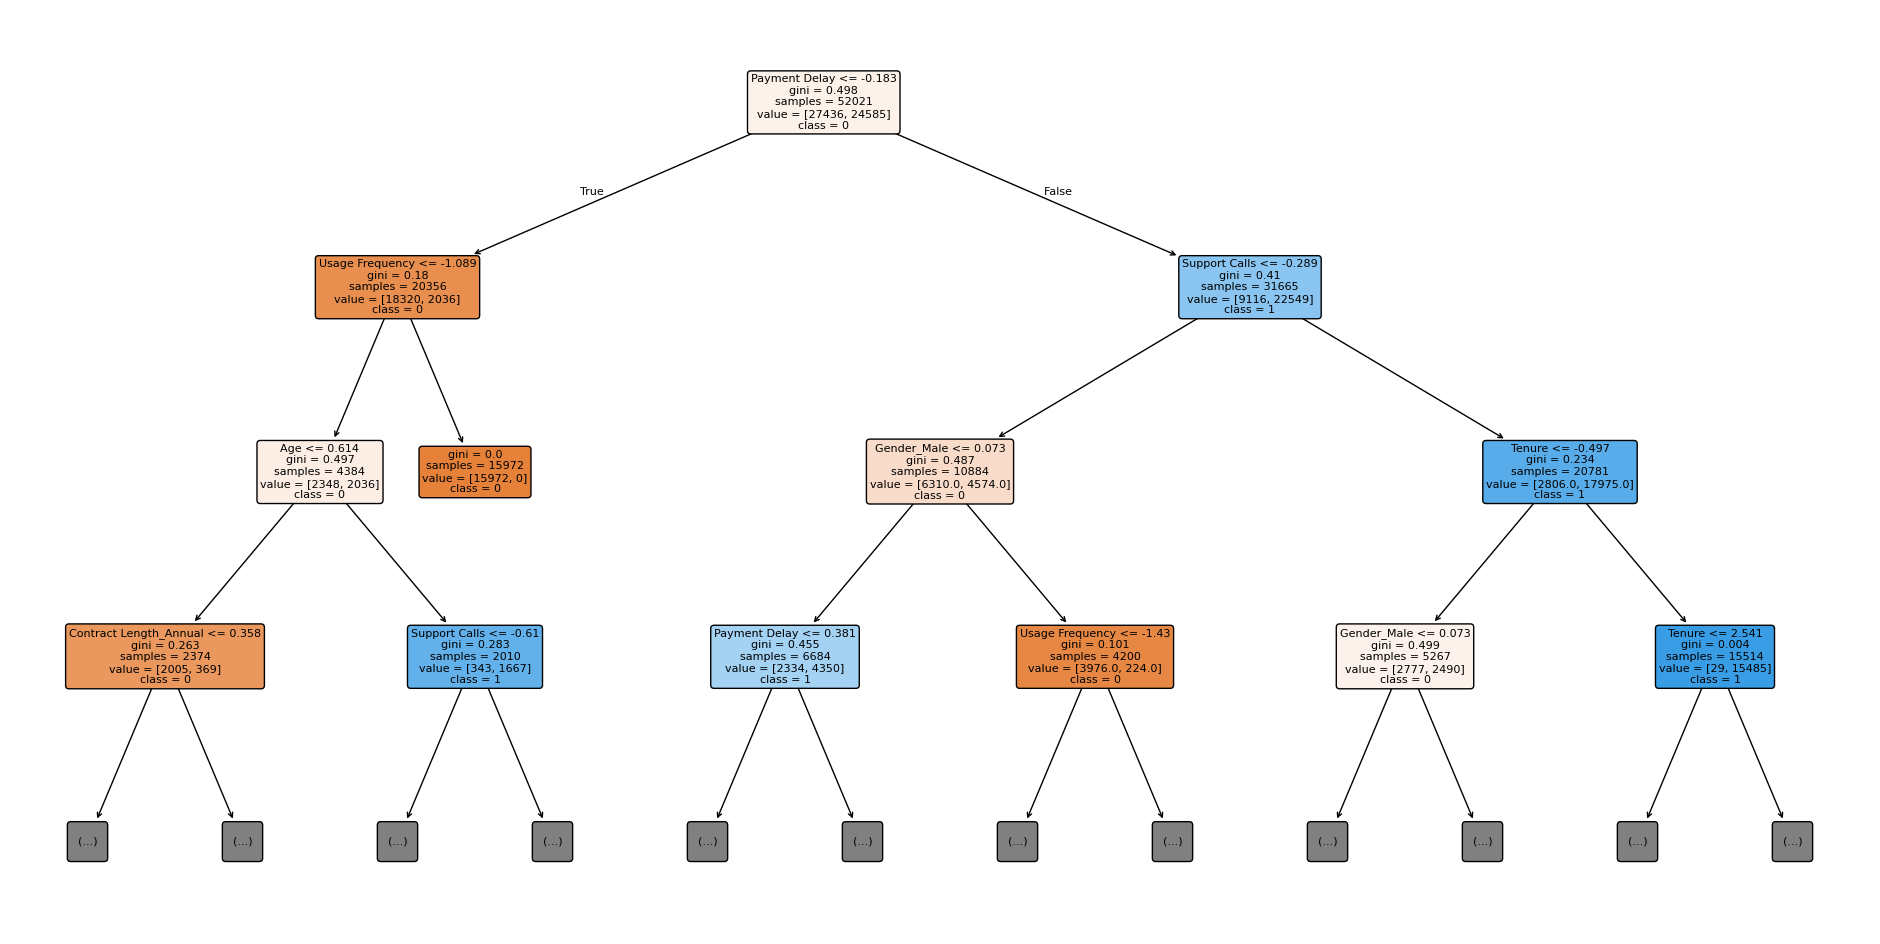

In [95]:
# Decision Tree Visualization
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(
    DT,
    filled=True,
    feature_names=train_data.columns,
    class_names=['0', '1'],
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.savefig("decision_tree.pdf", bbox_inches="tight")
plt.show()

In [96]:
#Train prediction values
dt_pred_train

array([1, 1, 1, ..., 1, 0, 1], shape=(52021,))

In [97]:
#Actual train values VS Prediction train values using the Decision Model
dt_pred_train_data= pd.DataFrame({'Actual_train':y_train,"Predicted_train":dt_pred_train})
dt_pred_train_data.head(5)

,Actual_train,Predicted_train
58633,1,1
56411,1,1
24061,1,1
52397,1,1
3290,1,1


In [98]:
#Test Prediction values
dt_pred_test

array([0, 1, 1, ..., 1, 0, 1], shape=(13006,))

In [99]:
#Actual test values VS Prediction test values
dt_pred_test_data= pd.DataFrame({'Actual':y_test,"Predicted_train":dt_pred_test})
dt_pred_test_data.head()

,Actual,Predicted_train
33497,0,0
33870,1,1
3224,1,1
38522,0,0
51556,1,1


In [100]:
#Evaluation Metrics [ACCURACY]
from sklearn.metrics import accuracy_score, classification_report
print("Train",accuracy_score(y_train,dt_pred_train))
print("Test",accuracy_score(y_test,dt_pred_test))

Train 1.0
Test 0.9941565431339382


In [101]:
#Classification Report for training data
print("Train: ",classification_report(y_train,dt_pred_train))

Train:                precision    recall  f1-score   support

           0       1.00      1.00      1.00     27436
           1       1.00      1.00      1.00     24585

    accuracy                           1.00     52021
   macro avg       1.00      1.00      1.00     52021
weighted avg       1.00      1.00      1.00     52021



In [102]:
#Classification Report for testing data
print("Test: ",classification_report(y_test,dt_pred_test))

Test:                precision    recall  f1-score   support

           0       0.99      0.99      0.99      6800
           1       0.99      0.99      0.99      6206

    accuracy                           0.99     13006
   macro avg       0.99      0.99      0.99     13006
weighted avg       0.99      0.99      0.99     13006



In [103]:
#AUC ROC score for Decision Tree
from sklearn.metrics import roc_auc_score,roc_curve
print("Train AUC ROC score: ", roc_auc_score(y_train,dt_pred_train))
print("Test AUC ROC score: ", roc_auc_score(y_test,dt_pred_test))


Train AUC ROC score:  1.0
Test AUC ROC score:  0.9941724801425564


In [104]:
#Graph
sigmoid= DT.predict_proba(test_data)[:,1]
sigmoid

array([0., 1., 1., ..., 1., 0., 1.], shape=(13006,))

In [105]:

auc_score= roc_auc_score(y_test,sigmoid)
auc_score

np.float64(0.9941724801425564)

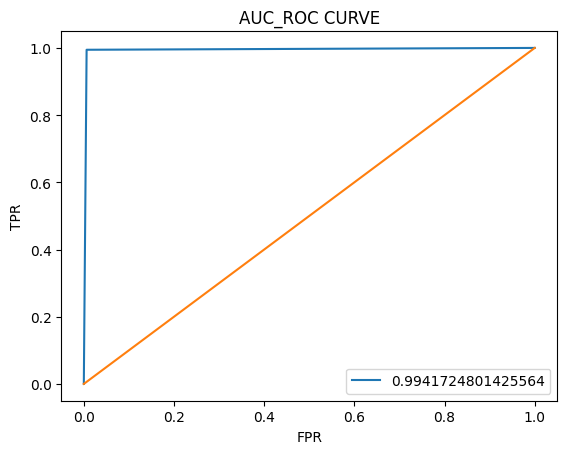

In [106]:
fpr,tpr,thr= roc_curve(y_test,sigmoid)
plt.plot(fpr,tpr,label= f'{auc_score}')
plt.plot([0,1])
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("AUC_ROC CURVE")
plt.legend()
plt.show()

                                               RANDOM FOREST MODEL

In [107]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
random= RandomForestClassifier(n_estimators=50,random_state=75,max_samples=0.3,max_features=0.7)
random.fit(train_data,y_train) #Model Train
pred_train= random.predict(train_data) #Model Prediction
pred_test= random.predict(test_data)

In [108]:
#Predicted train values
pred_train

array([1, 1, 1, ..., 1, 0, 1], shape=(52021,))

In [109]:
#Actual train values VS Prediction train values
pred_train_data= pd.DataFrame({'Actual_train':y_train,"Predicted_train":pred_train})
pred_train_data.head(5)

,Actual_train,Predicted_train
58633,1,1
56411,1,1
24061,1,1
52397,1,1
3290,1,1


In [110]:
#Predicted test values
pred_test

array([0, 1, 1, ..., 1, 0, 1], shape=(13006,))

In [111]:
#Actual test values VS Prediction test values
pred_test_data= pd.DataFrame({'Actual':y_test,"Predicted_train":pred_test})
pred_test_data.head()

,Actual,Predicted_train
33497,0,0
33870,1,1
3224,1,1
38522,0,0
51556,1,1


In [112]:
from sklearn.metrics import accuracy_score, classification_report
print("Train",accuracy_score(y_train,pred_train))
print("Test",accuracy_score(y_test,pred_test))

Train 0.9985582745429731
Test 0.9966938336152545


In [113]:
#F1 Score
from sklearn.metrics import f1_score
print("Train f1_score is: ",f1_score(y_train,pred_train))
print("Test f1_score is: ",f1_score(y_test,pred_test))

Train f1_score is:  0.9984746486607415
Test f1_score is:  0.9965308592174263


In [117]:
#Classification report for train data
print("Train: ", classification_report(y_train,pred_train))

Train:                precision    recall  f1-score   support

           0       1.00      1.00      1.00     27436
           1       1.00      1.00      1.00     24585

    accuracy                           1.00     52021
   macro avg       1.00      1.00      1.00     52021
weighted avg       1.00      1.00      1.00     52021



In [115]:
#Classification report for test data
print("Test: ", classification_report(y_test,pred_test))

Test:                precision    recall  f1-score   support

           0       1.00      1.00      1.00      6800
           1       1.00      1.00      1.00      6206

    accuracy                           1.00     13006
   macro avg       1.00      1.00      1.00     13006
weighted avg       1.00      1.00      1.00     13006



In [116]:
#Hyperparameter Turning
from sklearn.model_selection import GridSearchCV
param_grid= { 'n_estimators':[50,100,150,200],
              'max_features':[0.6,0.7,0.8,0.9],
              'max_depth':[5],
              'criterion':['gini','entropy'],
              'bootstrap':[True,False]
}
rf_model= RandomForestClassifier()
grid_search= GridSearchCV(estimator=rf_model,
                          param_grid=param_grid,cv=4)
grid_search.fit(train_data,y_train)

GridSearchCV(cv=4, estimator=RandomForestClassifier(),
             param_grid={'bootstrap': [True, False],
                         'criterion': ['gini', 'entropy'], 'max_depth': [5],
                         'max_features': [0.6, 0.7, 0.8, 0.9],
                         'n_estimators': [50, 100, 150, 200]})

In [118]:
print("Best Parameters: ",grid_search.best_params_)

Best Parameters:  {'bootstrap': True, 'criterion': 'entropy', 'max_depth': 5, 'max_features': 0.8, 'n_estimators': 200}


In [119]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest Classifier with Best Parameters
rf_model= RandomForestClassifier(n_estimators=200,criterion='entropy',bootstrap=True,max_features=0.8,
                                 random_state=78,max_depth=5)

#Model Training
rf_model.fit(train_data,y_train)


RandomForestClassifier(criterion='entropy', max_depth=5, max_features=0.8,
                       n_estimators=200, random_state=78)

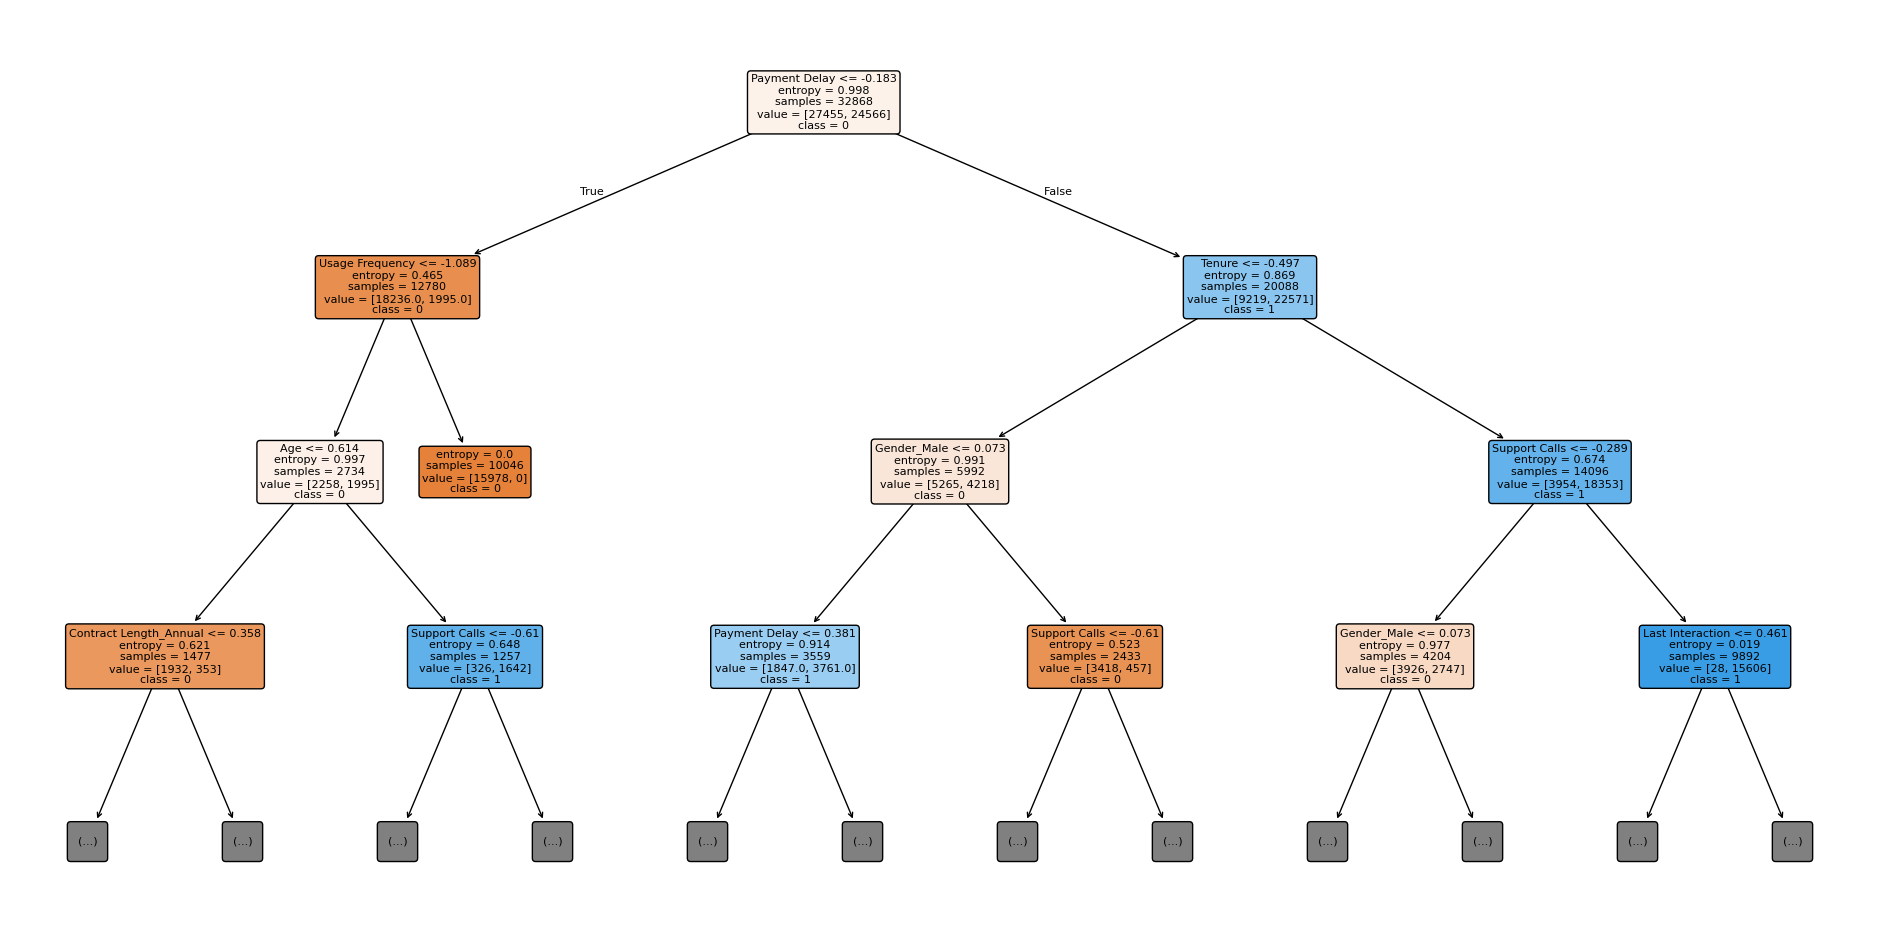

In [120]:
# Random Forest Decision Tree Visualization for n_estimator =0 (1st Decision Tree)
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
     rf_model.estimators_[0],
    filled=True,
    feature_names=train_data.columns,
    class_names=['0', '1'],
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.savefig("RandomForest_decision_tree_1.png", dpi=300, bbox_inches="tight")
plt.savefig("RandomForest_decision_tree_1.pdf", bbox_inches="tight")
plt.show()

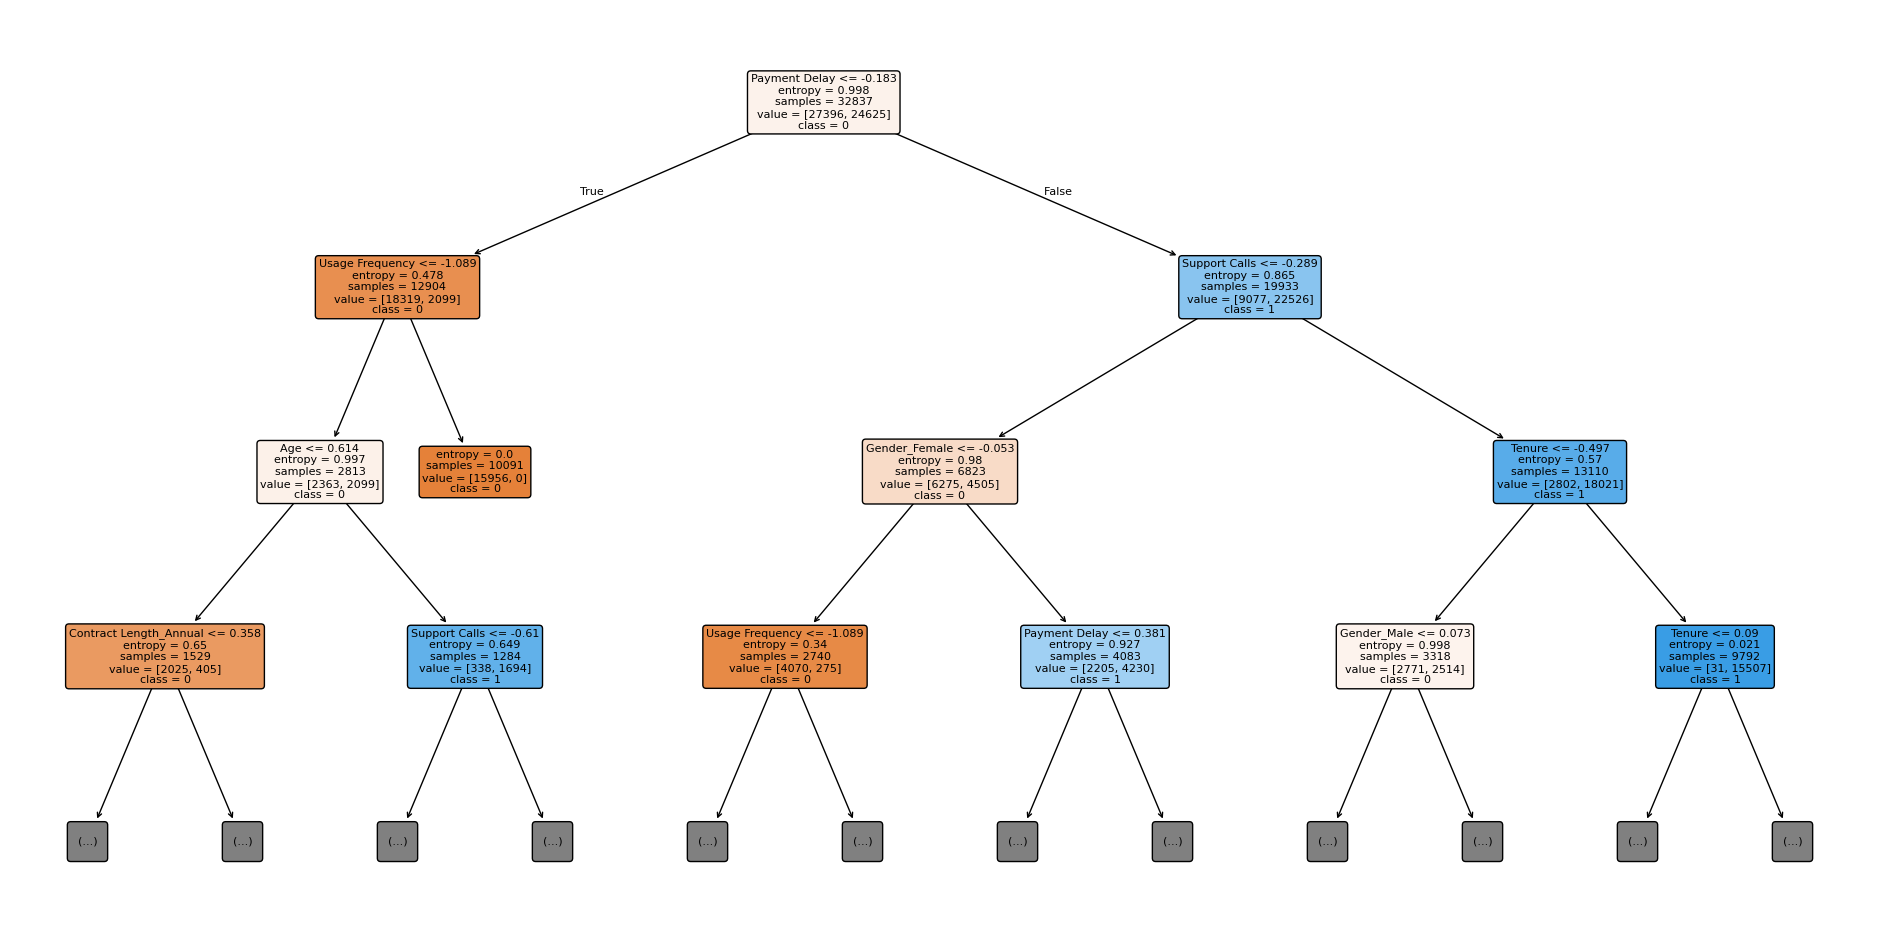

In [121]:
# Random Forest Decision Tree Visualization for n_estimator =199 (200th Decision Tree)
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
     rf_model.estimators_[199],
    filled=True,
    feature_names=train_data.columns,
    class_names=['0', '1'],
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.savefig("RandomForest_decision_tree_200.png", dpi=300, bbox_inches="tight")
plt.savefig("RandomForest_decision_tree_200.pdf", bbox_inches="tight")
plt.show()

In [122]:
#Model prediction
rf_pred_train= rf_model.predict(train_data) #Model Prediction for training data
rf_pred_test= rf_model.predict(test_data)  #Model Prediction for training data

In [123]:
#Prediction values with best parameters
rf_pred_train

array([1, 1, 1, ..., 1, 0, 1], shape=(52021,))

In [124]:
print(y_train.shape)
print(rf_pred_train.shape)

(52021,)
(52021,)


In [125]:
#Actual train values VS Best Parameters Prediction train values
rf_pred_best_train= pd.DataFrame({'Actual_train':y_train,"Predicted_train":rf_pred_train})
rf_pred_best_train.head(5)

,Actual_train,Predicted_train
58633,1,1
56411,1,1
24061,1,1
52397,1,1
3290,1,1


In [126]:
#Prediction values with best parameters
rf_pred_test

array([0, 1, 1, ..., 1, 0, 1], shape=(13006,))

In [127]:
#Actual test values VS Best Parameters Prediction test values
rf_pred_best_test= pd.DataFrame({'Actual_train':y_test,"Predicted_train":rf_pred_test})
rf_pred_best_test.head(5)

,Actual_train,Predicted_train
33497,0,0
33870,1,1
3224,1,1
38522,0,0
51556,1,1


In [128]:
#Evaluation metrics
#Accuracy
from sklearn.metrics import accuracy_score, f1_score, classification_report
print("Train data: ",accuracy_score(y_train,rf_pred_train))
print("Test data: ",accuracy_score(y_test,rf_pred_test))

Train data:  0.9776628669191288
Test data:  0.9747039827771797


In [129]:
#F1 score
print("Train data: ",f1_score(y_train,rf_pred_train))
print("Test data: ",f1_score(y_test,rf_pred_test))

Train data:  0.9762167915182774
Test data:  0.9732976219462706


In [130]:
#Classification report train data
print("Train data: ",classification_report(y_train,rf_pred_train))

Train data:                precision    recall  f1-score   support

           0       0.97      0.98      0.98     27436
           1       0.98      0.97      0.98     24585

    accuracy                           0.98     52021
   macro avg       0.98      0.98      0.98     52021
weighted avg       0.98      0.98      0.98     52021



In [131]:
#Classification report test data
print("Test data: ",classification_report(y_test,rf_pred_test))

Test data:                precision    recall  f1-score   support

           0       0.97      0.98      0.98      6800
           1       0.98      0.97      0.97      6206

    accuracy                           0.97     13006
   macro avg       0.98      0.97      0.97     13006
weighted avg       0.97      0.97      0.97     13006



                                             AUC AND DOC CURVE

In [132]:
#AUC ROC score
from sklearn.metrics import roc_auc_score
print("Train AUC ROC score: ", roc_auc_score(y_train,rf_pred_train))
print("Test AUC ROC score: ", roc_auc_score(y_test,rf_pred_test))


Train AUC ROC score:  0.9772658875339085
Test AUC ROC score:  0.9743308894618112


In [133]:
#Sigmoid values
rf_sigmoid= rf_model.predict_proba(test_data)[:,1]
rf_sigmoid

array([1.93996536e-05, 7.83271770e-01, 9.99746581e-01, ...,
       9.99717550e-01, 4.33608729e-05, 9.99796740e-01], shape=(13006,))

In [135]:
#AUC ROC SCORE
auc_score= roc_auc_score(y_test,rf_sigmoid)
print("ROC AUC SCORE: ",auc_score)

ROC AUC SCORE:  0.9973870874485792


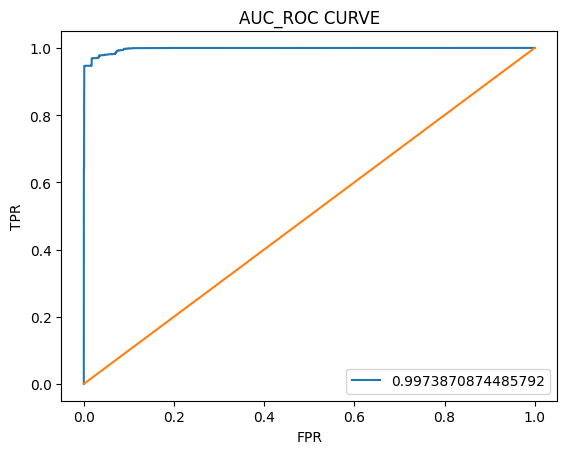

In [136]:
fpr,tpr,thr= roc_curve(y_test,rf_sigmoid)
plt.plot(fpr,tpr,label= f'{auc_score}')
plt.plot([0,1])
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("AUC_ROC CURVE")
plt.legend()
plt.show()

                                         DBSCAN

In [137]:
#Loading the dataset
x=pd.read_csv("/content/customer_churn_dataset_80000_records.csv")

In [138]:
#Top 5 records
x.head()


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22.0,Female,25.0,14,4,27,Basic,Monthly,598.0,9,1
1,2,41.0,Female,28.0,28,7,13,Standard,Monthly,584.0,20,0
2,3,47.0,Male,27.0,10,2,29,Premium,Annual,757.0,21,0
3,4,35.0,Male,9.0,12,5,17,Premium,Quarterly,232.0,18,0
4,5,53.0,Female,58.0,24,9,2,Standard,Annual,533.0,18,0


In [139]:
x['CustomerID'].nunique()

79900

In [140]:
x[x['CustomerID'].duplicated(keep=False)].sort_values('CustomerID')

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
286,287,61.0,NaN,46.0,5,2,3,Premium,Annual,501.0,21,0
64383,287,61.0,NaN,46.0,5,2,3,Premium,Annual,501.0,21,0
649,650,61.0,Female,32.0,20,7,26,Basic,Quarterly,908.0,3,1
64428,650,61.0,Female,32.0,20,7,26,Basic,Quarterly,908.0,3,1
64376,928,56.0,Male,NaN,7,2,6,Premium,Annual,204.0,24,0
...,...,...,...,...,...,...,...,...,...,...,...,...
62198,62199,34.0,Female,19.0,10,10,29,Basic,Annual,219.0,22,1
62437,62438,44.0,Male,NaN,10,9,23,Basic,Quarterly,795.0,23,1
64391,62438,44.0,Male,NaN,10,9,23,Basic,Quarterly,795.0,23,1
62926,62927,55.0,Female,16.0,12,4,28,Premium,Annual,131.0,23,1


In [141]:
#Removing the duplicate records
x = x.drop_duplicates(subset=['CustomerID'], keep='first')

In [142]:
x['CustomerID'].nunique()

79900

In [143]:
#Droping the unwanted columns
x.drop(columns=['CustomerID','Churn'],inplace=True)


In [144]:
#Checking the columns are dropped or not
x.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction
0,22.0,Female,25.0,14,4,27,Basic,Monthly,598.0,9
1,41.0,Female,28.0,28,7,13,Standard,Monthly,584.0,20
2,47.0,Male,27.0,10,2,29,Premium,Annual,757.0,21
3,35.0,Male,9.0,12,5,17,Premium,Quarterly,232.0,18
4,53.0,Female,58.0,24,9,2,Standard,Annual,533.0,18


In [145]:
x.shape

(79900, 10)

In [146]:
x.size

799000

In [147]:
#checking the null values
x.isnull().sum()

,0
Age,644
Gender,644
Tenure,644
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,644
Contract Length,0
Total Spend,644
Last Interaction,0


In [148]:
#Replacing the null values categorical data mode
temp= x.select_dtypes(include=['object']).columns
for i in temp:
    x[i]= x[i].fillna(x[i].mode()[0])

In [149]:
#Replacing the null values of numerical columns with mean or median
temp1= x.select_dtypes(include=['int64','float64']).columns
for i in temp1:
    x[i]= x[i].fillna(x[i].median())

In [150]:
#Checking null values are dropped or not
x.isnull().sum()

,0
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0
Last Interaction,0


In [151]:
#Checking duplicate records are removed or not
x.duplicated().sum()

np.int64(15002)

In [152]:
x.dtypes

,0
Age,float64
Gender,object
Tenure,float64
Usage Frequency,int64
Support Calls,int64
Payment Delay,int64
Subscription Type,object
Contract Length,object
Total Spend,float64
Last Interaction,int64


In [153]:
#Encoding Tech
x= pd.get_dummies(x,columns=['Gender', 'Subscription Type', 'Contract Length'],dtype='int')

In [154]:
x.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
0,22.0,25.0,14,4,27,598.0,9,1,0,1,0,0,0,1,0
1,41.0,28.0,28,7,13,584.0,20,1,0,0,0,1,0,1,0
2,47.0,27.0,10,2,29,757.0,21,0,1,0,1,0,1,0,0
3,35.0,9.0,12,5,17,232.0,18,0,1,0,1,0,0,0,1
4,53.0,58.0,24,9,2,533.0,18,1,0,0,0,1,1,0,0


In [155]:
#Applying the Scaling Tech
from sklearn.preprocessing import MinMaxScaler
sc= MinMaxScaler()
data= sc.fit_transform(x)

In [156]:
data= pd.DataFrame(data, columns=x.columns)
data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
0,0.014184,0.016011,0.008672,0.013333,0.018000,0.002491,0.005337,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.081560,0.018012,0.018012,0.023333,0.008667,0.002421,0.012675,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.102837,0.017345,0.006004,0.006667,0.019333,0.003287,0.013342,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.060284,0.005337,0.007338,0.016667,0.011333,0.000660,0.011341,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.124113,0.038025,0.015344,0.030000,0.001333,0.002166,0.011341,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


In [157]:
data.isnull().sum().sum()

np.int64(0)

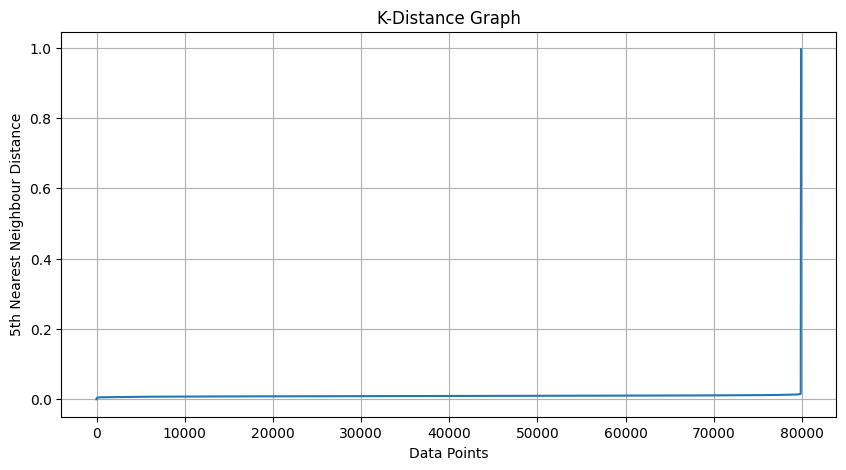

In [158]:
# K-Distance Graph for selecting eps
from sklearn.neighbors import NearestNeighbors
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(data)
distances, indices = neighbors_fit.kneighbors(data)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances)

plt.xlabel('Data Points')
plt.ylabel('5th Nearest Neighbour Distance')
plt.title('K-Distance Graph')
plt.grid()
plt.show()

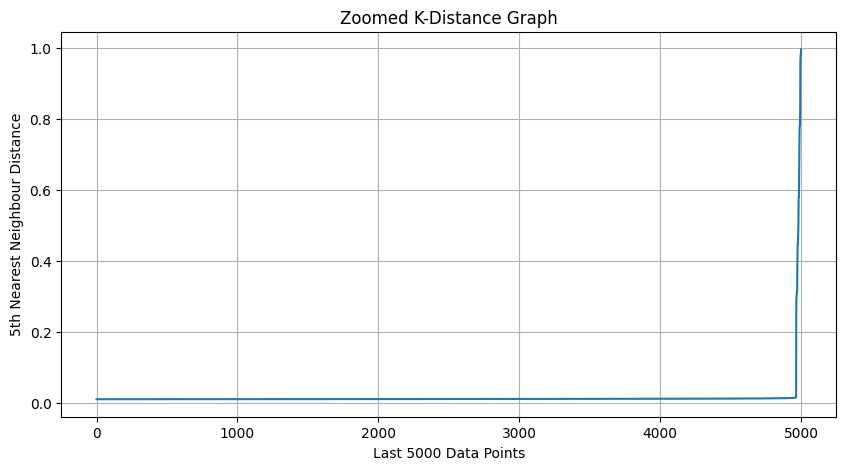

In [159]:
# Zooming into the elbow region

plt.figure(figsize=(10, 5))

plt.plot(distances[-5000:])

plt.xlabel('Last 5000 Data Points')
plt.ylabel('5th Nearest Neighbour Distance')

plt.title('Zoomed K-Distance Graph')

plt.grid()
plt.show()

In [160]:
#DBSCAN model to get the eps value
from sklearn.cluster import DBSCAN
eps_values=[0.40,0.50,0.6,0.7,0.8,0.9]
for eps in eps_values:
    dbscan= DBSCAN(eps=eps, min_samples=5)
    labels= dbscan.fit_predict(data)
    clusters = len(set(labels) - {-1})
    noise = (labels == -1).sum()

    print("Epsilon:", eps)
    print("Number of Clusters:", clusters)
    print("Noise Points:", noise)
    print("Noise Percentage:", (noise / len(data)) * 100)
    print("-------------------------")

Epsilon: 0.4
Number of Clusters: 18
Noise Points: 25
Noise Percentage: 0.03128911138923655
-------------------------
Epsilon: 0.5
Number of Clusters: 18
Noise Points: 18
Noise Percentage: 0.022528160200250315
-------------------------
Epsilon: 0.6
Number of Clusters: 18
Noise Points: 14
Noise Percentage: 0.017521902377972468
-------------------------
Epsilon: 0.7
Number of Clusters: 18
Noise Points: 13
Noise Percentage: 0.016270337922403004
-------------------------
Epsilon: 0.8
Number of Clusters: 18
Noise Points: 6
Noise Percentage: 0.007509386733416771
-------------------------
Epsilon: 0.9
Number of Clusters: 18
Noise Points: 4
Noise Percentage: 0.0050062578222778474
-------------------------


In [161]:

from sklearn.cluster import DBSCAN
dbscan= DBSCAN(eps=0.7,min_samples=5)
dbscan.fit(data)
dbscan.labels_

array([ 0,  1,  2, ...,  6, 11, 10], shape=(79900,))

In [162]:
# Adding cluster labels separately

clustered_data = data.copy()
clustered_data['cluster'] = dbscan.labels_


In [163]:
clustered_data.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly,cluster
0,0.014184,0.016011,0.008672,0.013333,0.018000,0.002491,0.005337,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0
1,0.081560,0.018012,0.018012,0.023333,0.008667,0.002421,0.012675,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1
2,0.102837,0.017345,0.006004,0.006667,0.019333,0.003287,0.013342,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,2
3,0.060284,0.005337,0.007338,0.016667,0.011333,0.000660,0.011341,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,3
4,0.124113,0.038025,0.015344,0.030000,0.001333,0.002166,0.011341,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,4


In [164]:
#To get the no of clusters
set(dbscan.labels_)

{np.int64(-1),
 np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17)}

In [165]:
#getting the noise data
clustered_data[clustered_data['cluster']==-1].head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly,cluster
2160,0.095745,1.000000,0.014009,0.000000,0.009333,0.002971,0.008672,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,-1
8493,0.060284,0.017345,0.017345,0.833333,0.008000,0.001596,0.009340,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,-1
15318,0.024823,0.015344,0.012675,1.000000,0.004667,0.002171,0.007338,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,-1
18337,0.056738,0.006671,0.013342,0.030000,0.800000,0.004297,0.014009,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,-1
19076,0.010638,0.038025,0.007338,0.000000,0.009333,0.002156,0.799867,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,-1


In [166]:
#Getting the count of churn data points
count = (dbscan.labels_== -1).sum()
print("Noise count: ",count)

Noise count:  13


In [167]:
#Clusterwise data points count
clustered_data['cluster'].value_counts().sort_index()

,count
cluster,
-1,13
0,4996
1,5184
2,4096
3,3995
4,4751
5,4052
6,4720
7,4068


In [168]:
#Evaluation metrics for DBSCAN model
from sklearn.metrics import silhouette_score

labels = dbscan.labels_
mask = labels != -1

if len(set(labels[mask])) > 1:
    score = silhouette_score(data.loc[mask],
                             labels[mask])
    print("Silhouette Score:", score)
else:
    print("Silhouette score cannot be calculated.")

Silhouette Score: 0.9538441434061836


In [169]:
#Using the PCA Model for Dimensionality Reduction
from sklearn.decomposition import PCA
pca= PCA(n_components=2)
pca_data= pca.fit_transform(data)
pca_df= pd.DataFrame(pca_data,columns=['PCA_1','PCA_2',],index=data.index)
pca_df.head()

,PCA_1,PCA_2
0,-0.712380,0.780820
1,-0.691977,0.296466
2,0.798953,-0.174052
3,0.777117,0.049285
4,-0.604782,-0.881663


In [170]:
pca_df.shape

(79900, 2)

In [171]:
pca_df.size

159800

In [172]:
pca_df['cluster']=dbscan.labels_
pca_df.head()

,PCA_1,PCA_2,cluster
0,-0.712380,0.780820,0
1,-0.691977,0.296466,1
2,0.798953,-0.174052,2
3,0.777117,0.049285,3
4,-0.604782,-0.881663,4


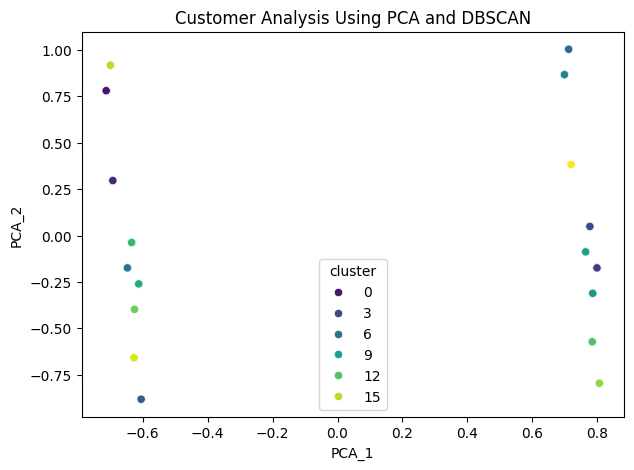

In [173]:
#Visualization
plt.figure(figsize=(7,5))
sns.scatterplot(data=pca_df,
                x='PCA_1',
                y='PCA_2',
                hue='cluster',
                palette='viridis')
plt.title("Customer Analysis Using PCA and DBSCAN")
plt.show()

In [174]:
import joblib
joblib.dump(dbscan,'dbscan_model.pkl')

['dbscan_model.pkl']

In [175]:
import joblib
joblib.dump(DT,'DT_model.pkl')

['DT_model.pkl']

In [176]:
import joblib
joblib.dump(rf_model,'rf_model.pkl')

['rf_model.pkl']

In [177]:
import joblib
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']

In [178]:
import joblib
joblib.dump(sc,"MinMax_scaler.pkl")

['MinMax_scaler.pkl']

In [182]:
import os
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Save lower and upper bounds
joblib.dump(lower_bound, "models/lower_bound.pkl")
joblib.dump(upper_bound, "models/upper_bound.pkl")

print("Lower and Upper bounds saved successfully!")

Lower and Upper bounds saved successfully!


In [181]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful